# 06 — BGL exploration

Per-line labels (alert = anomaly). Questions before modelling:
- How well do log levels match the labels?
- How are alerts distributed over time?
- Do templates determine labels?
- Which window size gives usable sessions?

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Project root not found")
    ROOT = ROOT.parent
OUT = ROOT / "data" / "processed"

events = np.load(OUT / "bgl_events.npz")
ts, alert = events["timestamp"], events["alert"]
level_names = events["level_names"][events["level"]]
category_names = events["category_names"][events["category"]]
template = events["template"]
templates = pd.read_csv(OUT / "bgl_templates.csv")
info = json.loads((OUT / "bgl_parse_info.json").read_text())

print(json.dumps(info, indent=2))
print(f"\nTimestamps in order: {bool(np.all(np.diff(ts) >= 0))}")

{
  "lines_read": 4747963,
  "lines_malformed": 0,
  "lines_parsed": 4747963,
  "alert_lines": 348460,
  "templates": 2845,
  "first_utc": "2005-06-03T22:42:50+00:00",
  "last_utc": "2006-01-04T16:00:05+00:00",
  "drain_sim_threshold": 0.9,
  "drain_depth": 4,
  "masks": [
    "NODE",
    "HEX",
    "BLK",
    "IP",
    "UUID",
    "HEX",
    "PATH",
    "NUM"
  ],
  "seconds": 109.9
}

Timestamps in order: True


In [2]:
table = pd.crosstab(pd.Series(level_names, name="level"), pd.Series(np.where(alert, "Alert", "Normal"), name="label"))
table["alert_%_of_level"] = (100 * table.get("Alert", 0) / table.sum(axis=1)).round(2)
display(table)

# A naive rule: FATAL (or worse) means anomaly, at line level
severe = np.isin(level_names, ["FATAL", "FAILURE", "SEVERE", "ERROR"])
tp, fp, fn = int((severe & alert).sum()), int((severe & ~alert).sum()), int((~severe & alert).sum())
print(f"Rule 'level is ERROR/SEVERE/FATAL/FAILURE' at line level: precision {tp / max(tp + fp, 1):.3f}, "
      f"recall {tp / max(tp + fn, 1):.3f}")

label,Alert,Normal,alert_%_of_level
level,,,
"0x00544eb8,",0,2,0.00
ERROR,0,112355,0.00
FAILURE,62,1652,3.62
FATAL,348398,506797,40.74
INFO,0,3735813,0.00
Kill,0,306,0.00
SEVERE,0,19213,0.00
WARNING,0,23357,0.00
microseconds,0,4,0.00


Rule 'level is ERROR/SEVERE/FATAL/FAILURE' at line level: precision 0.353, recall 1.000


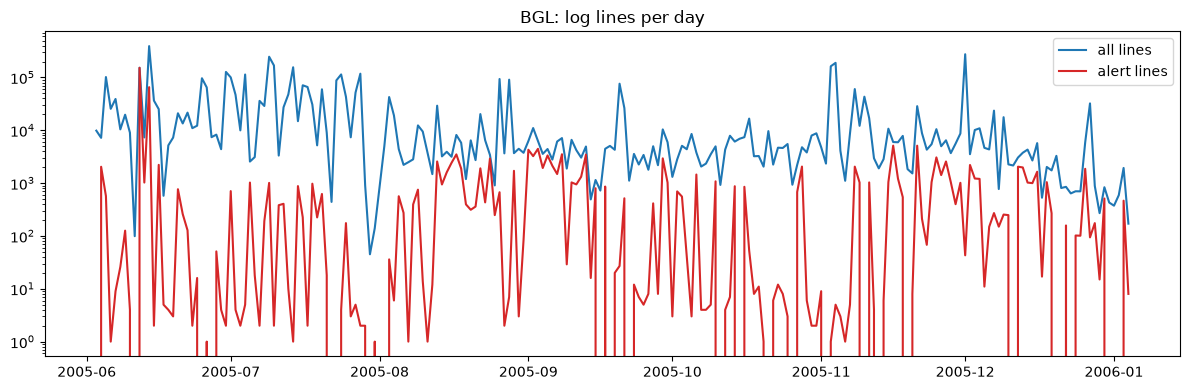

Days with any alert: 189 of 215
Share of all alerts in the 5 busiest alert days: 66.7%


In [3]:
days = pd.to_datetime(ts, unit="s").floor("D")
per_day = pd.DataFrame({"day": days, "alert": alert}).groupby("day")["alert"].agg(lines="size", alerts="sum")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(per_day.index, per_day["lines"], label="all lines")
ax.plot(per_day.index, per_day["alerts"], label="alert lines", color="tab:red")
ax.set_yscale("log")
ax.set_title("BGL: log lines per day")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Days with any alert: {(per_day['alerts'] > 0).sum()} of {len(per_day)}")
print(f"Share of all alerts in the 5 busiest alert days: "
      f"{100 * per_day['alerts'].nlargest(5).sum() / per_day['alerts'].sum():.1f}%")

In [4]:
categories = pd.Series(category_names[alert]).value_counts()
print(f"{len(categories)} alert categories")
display(categories.head(15).to_frame("alert lines"))

41 alert categories


,alert lines
KERNDTLB,152734
KERNSTOR,63491
APPSEV,49651
KERNMNTF,31531
KERNTERM,23338
KERNREC,6145
APPREAD,5983
KERNRTSP,3983
APPRES,2370
APPUNAV,2048


In [5]:
per_template = (pd.DataFrame({"template_id": template, "alert": alert})
                .groupby("template_id")["alert"].agg(lines="size", alert_share="mean"))
groups = pd.cut(per_template["alert_share"], [-0.01, 0.0, 0.999999, 1.0],
                labels=["never alert", "mixed", "always alert"])
summary = per_template.groupby(groups, observed=False).agg(templates=("lines", "size"), lines=("lines", "sum"))
display(summary)

mixed = per_template[groups == "mixed"].join(templates.set_index("template_id")["template"])
print("Mixed templates (same message, sometimes alert, sometimes not):")
display(mixed.sort_values("lines", ascending=False).head(10))

,templates,lines
alert_share,,
never alert,728,4395837
mixed,4,68666
always alert,2113,283460


Mixed templates (same message, sometimes alert, sometimes not):


,lines,alert_share,template
template_id,,,
162,63493,0.999969,data storage interrupt
211,3667,0.001364,program interrupt
366,1504,0.999335,Microloader Assertion
325,2,0.500000,ciodb exited normally with exit code <NUM>


In [6]:
t0 = ts.min()
rows = []
for seconds, name in ((60, "1 min"), (300, "5 min"), (900, "15 min"), (1800, "30 min"),
                      (3600, "1 h"), (6 * 3600, "6 h")):
    window = (ts - t0) // seconds
    grouped = pd.DataFrame({"window": window, "alert": alert}).groupby("window")["alert"].agg(["size", "any"])
    rows.append({
        "window": name,
        "non_empty_windows": len(grouped),
        "anomalous_windows": int(grouped["any"].sum()),
        "anomalous_%": round(100 * grouped["any"].mean(), 2),
        "median_lines": int(grouped["size"].median()),
    })
display(pd.DataFrame(rows))

,window,non_empty_windows,anomalous_windows,anomalous_%,median_lines
0,1 min,27659,1808,6.54,4
1,5 min,14501,1052,7.25,6
2,15 min,8590,858,9.99,12
3,30 min,5773,758,13.13,20
4,1 h,3607,665,18.44,49
5,6 h,826,409,49.52,752


## Findings
- 4,747,963 lines, 0 malformed; 348,460 alert lines (7.34%); 41 alert categories (KERNDTLB 44% of alerts);
  2,845 templates (more than in the first 200k lines; rare templates to be checked before features).
- Levels vs labels: 99.98% of alerts are FATAL, but only 40.7% of FATAL lines are alerts. Rule "FATAL or worse":
  precision 0.353, recall 1.000 (line level). ERROR/SEVERE/WARNING lines are never alerts.
  ~316 lines have a shifted level column (minor parsing artefact).
- Alerts are bursty: alerts on 189 of 215 days, but the 5 busiest days hold 66.7% of all alerts.
- Templates almost determine labels: 728 templates never alert (4.40 M lines), 2,113 always alert (0.28 M lines),
  only 4 mixed (68,666 lines), and those are nearly pure.
- Prediction: "window contains a template unseen in training normals" will be a very strong baseline.
- Window size chosen: 15 minutes (8,590 non-empty windows, 9.99% anomalous, median 12 lines).